## 1. AI 에이전트  

### 1-1 AI에이전트의 정의 / 생성형 AI vs 에이전틱 AI  

> AI에이전트란? 사용자가 정한 목표를 달성하기 위해 AI모델을 활용해 환경과 상호작용하는 시스템  

- 생성형 AI : 프롬프트에 맞는 결과물을 한 번 출력하고 끝  
- 에이전틱 AI : 목표를 달성할 때까지 추론과 행동을 반복  

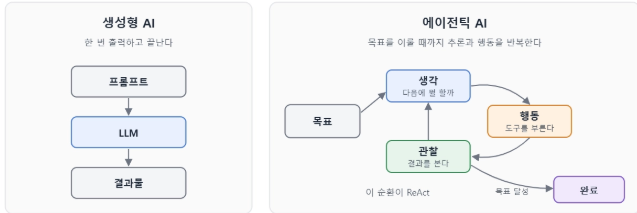  


### 1-2 ReAct(생각 -> 행동 -> 관찰)   

ReAct, 에이전틱 AI의 핵심 작동 방식 : 생각 -> 행동 -> 관찰 -> 생각의 순환 반복  

- Example of ReAct  

|  | 생각 | 행동 | 관찰 |
| --- | --- | --- | --- |
| 1 | 주문 상태부터 확인 | get_order(1234) | 4일 지연 중 |
| 2 | 지연 원인 확인 | track_shipment() | 배송사 서버 응답 없음 (시간 초과) |
| 3 | 일시적 오류일 수 있으니 재시도 | track_shipment() 재시도 | 물류센터 적체로 2일 추가 지연 |
| 4 | 배송비 환불 대상 | 사과 + 환불안 작성 | 초안 완성 |
| 5 | 돈이 나가니 확인 필요 | 담당자 승인 요청 | 승인 |
| 6 | 실행 | 환불 + 메시지 발송 | 완료 -> 종료 |

- If, 재시도가 계속 실패시 -> 상담원 연결 안내로 계획 변경  
i.e. 관찰결과에 따라 다음 생각이 달라짐  

- Example of 에이전틱 AI  
    - 세일즈 에이전트  
    - 데이터 분석/금융 에이전트  
    - 고객 서비스 응대 에이전트  


### 1-3 다중에이전트 : 오케스트레이터 + 서브 에이전트  

> MAS(멀티 에이전트) : 여러 에이전트가 역할을 나눠 함께 일하는 구조  
-> 가장 흔한 형태 = 오케스트레이터 + 서브 에이전트  
- 오케스트레이터 : 요청을 작은 일로 분할 -> 누구에게 맡길지 결정 -> 결과를 하나로 합침  
- 서브 에이전트 : 맡은 역할 하나만 *e.g. 검색봇은 검색만, 검토봇은 검토만(전문가)*  

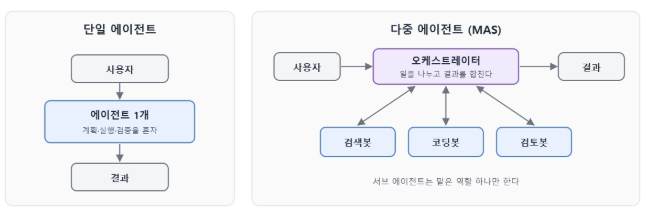  

**역할을 나누는 이유**  
- 스스로 실수를 잡기 어려움  
    - 단일 에이전트 -> 계획, 실행, 검증을 혼자 함 -> 처음 판단을 그대로 믿고 넘어가기 쉬움  
    - 검토를 다른 에이전트에게 -> 처음 보는 눈으로 다시 확인  

- 동시에 여러 갈래를 조사  
    - 서브 에이전트마다 자기 작업 공간(컨텍스트 창) -> 더 빠르고, 한 에이전트가 기억할 양도 줄어듦  

**역할을 나누는 경우**  

|  | 언제 쓰나요 | 예시 |
| --- | --- | --- |
| 고정 워크플로우 | 순서가 정해진 단순 작업 | 매일 아침 신규 주문 정리 -> 메일 발송 |
| 단일 에이전트 | 도구 몇 개로 해결되는 작업 | 앞에서 본 배송 지연 처리 |
| 다중 에이전트 | 따로 조사해서 합칠 수 있는 큰 작업 | S&P 500 IT 기업 이사진 조사 |  

**비용, 성능의 조합**  
모든 역할에 가장 비싼 모델 사용 X -> 역할마다 필요한 능력에 맞춰 급이 다른 모델 섞어서 사용

| 역할 | 모델 | 이유 |
| --- | --- | --- |
| 오케스트레이터 | 고성능 모델 (예: Claude Opus) | 일을 쪼개고 판단하는 능력이 전체 품질을 좌우 |
| 검색·정리봇 | 경량 모델 (예: Claude Haiku) | 단순 작업이 많아 빠르고 싼 모델이면 충분 |
| 코드 검증봇 | 코드 특화 모델 | 한 가지 일을 잘하는 모델이 유리 |


## 2. MCP(Model Context Protocol)  

### 2-1 도구 호출의 원리  

> Function Calling / Tool Calling : 모델이 '이 함수를 이 인자로 불러줘'라는 구조화된 요청을 내놓는 기능 -> 실제 실행과 결과 전달은 앱이 담당  

**호출 과정**  
1. 앱 -> 모델 : 질문 + 쓸 수 있는 함수 목록  
2. 모델 : 어떤 함수를 어떤 값으로 부를지 적어서 반환  
3. 앱 : 그 함수를 실제로 실행  
4. 앱 -> 모델 : 실행 결과 전달 -> 모델이 최종 답 작성  

- 표준이 없을 떄 : 앱마다 x 도구마다 연동 코드 따로 작성 -> n x m 개  
- 표준이 있을 때 : 앱은 MCP클라이언트 1번, 도구는 MCP서버 1번만 -> n + m 개  


**Function Calling vs MCP**  
둘은 경쟁관계 X, 대부분의 시스템은 둘 다 사용  

|  | Function Calling | MCP |
| --- | --- | --- |
| 위치 | 모델 API 쪽 기능 | 그 위의 연동 계층 |
| 하는 일 | 모델이 도구 호출 요청을 내놓는 방법 | 앱이 도구를 찾고·연결하고·호출하는 방법 |  

-> MCP로 도구 목록을 가져옴 -> 모델이 Function Calling으로 하나 고름 -> 앱이 다시 MCP로 실행  

### 2-2 MCP가 필요한 이유  

> MCP(Model Context Protocol) : LLM 앱(호스트, 클라이언트)과 외부 데이터, 도구(서버)가 통신하는 개방형 표준 프로토콜  
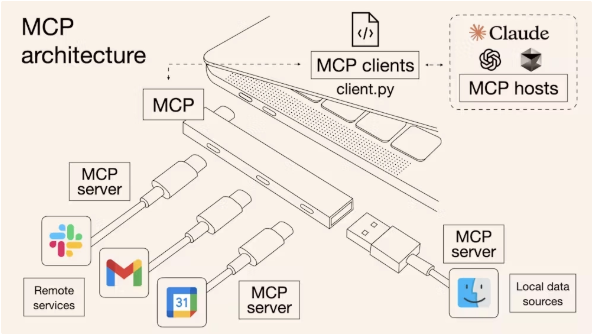  

**MCP도입으로 해결된 점**  
1. n x m -> n + m : 서버를 한 번 만들면 MCP를 지원하는 모든 앱에서 동작   
2. 발견의 표준화 : 클라이언트가 쓸 수 있는 도구를 물으면 서버가 목록 반환  
3. 원격 서버 인증 통일 : 인증 필요하면 OAuth로그인 표준을 따름  

### 2-3 MCP의 구조   

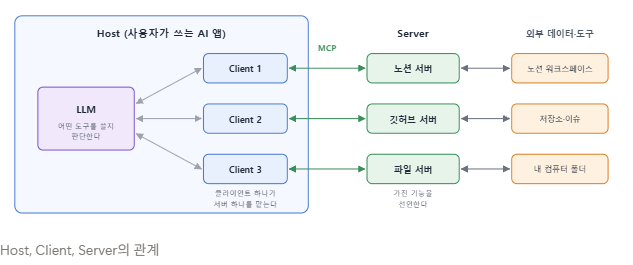  

#### 역할 정리 표   

| 역할 | 정체 | 하는 일 | 예시 |
| --- | --- | --- | --- |
| Host | 사용자가 쓰는 AI 앱 | LLM을 품고 클라이언트를 만들고 관리 / 어떤 서버, 도구 호출을 허용할지 결정 | Claude 데스크톱, Cursor |
| Client | 호스트 안의 통신 담당 | 서버 1개당 1개 -> MCP 규격으로 메시지 전달만 | 서버 3개 -> 클라이언트 3개 |
| Server | 도구, 데이터를 MCP 규격으로 내놓는 프로그램 | 가진 기능 선언 -> 요청이 오면 실제 작업 수행 | 노션 서버, 깃허브 서버 |


#### MCP 서버의 기본 요소   

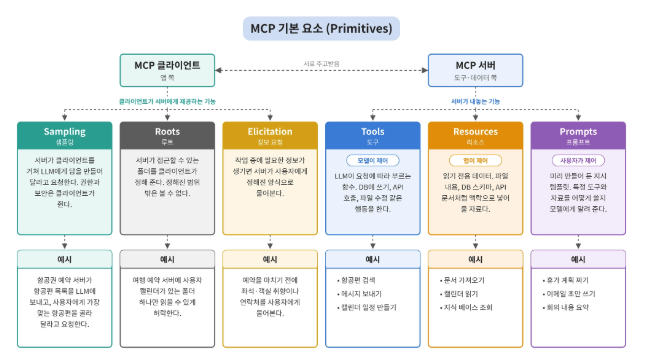  

1. Tools : 실행할 수 있는 행동  
    - e.g. 노션 페이지 만들기, 깃허브 이슈 등록하기  
2. Resources : 읽기 전용 데이터  
    - e.g. 파일 내용, 문서, DB스키마  
3. Prompts : 재사용 가능한 템플릿  
    - e.g. 코드 리뷰 요청 양식, 회의록 요약 양식  

-> RAG가 참고할 문서를 Resources로 넘길 수 있음  

### 2-4 MCP의 작동흐름  

- Example : 노션 MCP서버가 연결된 AI앱에서, 사용자가 '이번 주 회의록 요약해줘' 라고 한 상황  

**질문 전 : 미리 준비**  

| 단계 | 누가 -> 누구에게 | 무엇을 |
| --- | --- | --- |
| 연결 | 호스트 -> 노션 서버 | 노션 로그인(OAuth), 접근 허락 |
| 도구 목록 요청 | 클라이언트 -> 서버 | tools/list |
| 도구 목록 응답 | 서버 -> 클라이언트 | 도구 이름, 설명, 입력 형식 |  

**질문 후**  

| 단계 | 누가 -> 누구에게 | 무엇을 |
| --- | --- | --- |
| 질문 | 사용자 -> 호스트 | '이번 주 회의록 요약해 줘' |
| 전달 | 호스트 > 모델 | 질문 + 도구 목록 |
| 도구 선택 | 모델 -> 호스트 | search_pages 호출 요청만 (실행 X) |
| 호출 | 호스트 -> 클라이언트 -> 서버 | 허용 여부 확인 -> tools/call |
| 실행 | 서버 | 노션에서 실제 검색 |
| 결과 전달 | 서버 -> 클라이언트 -> 호스트 -> 모델 | 검색 결과를 대화에 넣어 줌 |
| 답변 | 모델 -> 사용자 | 회의록 요약 |  

i.e. 모델이 하는일 = 도구 고르기 + 답 쓰기  
연결, 호출, 실행 = 호스트, 클라이언트, 서버 담당


### 2-5 MCP의 한계  

#### 보안 책임은 누구에게 있는가?  

보안은 책임은 프로토콜이 아니라 호스트가 책임짐!  
- 사용자 동의, 서버에 넘길 권한 범위, 허용할 도구 선택 = 모두 호스트 몫  
- MCP는 연결하는 법만 정함, 무엇을 허락할지는 정하지 X

#### MCP를 사용할떄 주의할 점  

MCP 사용시 연결이 쉬워진 만큼 공격받을 틈도 넓어진다  

1. 신뢰할 수 없는 서버를 붙이는 위험  
    - MCP 서버는 누구나 만들어 올릴 수 있음  
    - 출처 모를 서버 연결 = 출처 모를 프로그램 설치  

2. 도구 설명을 통한 주입
> 도구 오염(tool Poisoning) : 도구 설명(description)안에 사용자에겐 안 보이고 모델에거만 보이는 지시를 숨기는 공격  
- 모델은 description 전체를 읽고 행동  

3. 너무 넓은 권한 연동의 위험  
    - 프롬프트 주입 문제 발생 가능   

**Q. 안전하게 외부 도구를 쓰려면?**  
=> 공식, 검증된 서버만 연결하고 필요한 권한만 주기, 되돌리기 어려운 호출은 사람이 직접 승인하고, 처음 연결하는 서버는 도구 설명 직접 확인하기  


## 3. 데이터 구조화 - (그래프, 온톨로지)  

### 구조화의 필요 이유  
에이전틱 AI, 피지컬 AI가 일하려면 구조화된 데이터가 필요한데, 이때 가장 흔한 방법은 RAG이지만, 단순히 문서를 벡터 DB로 만드는것만으로는 한계가 존재  

**Vanilla RAG 한계**  
> Top-K 딜레마? RAG에서 질문과의 유사도가 가장 높은 상위 k개의 문서조각만 선택하여 LLM에 전달하는 검색방식  

k설정에 따라 답변 품질이 좌우됨  
- k가 작으면 -> 필요한 정보를 놓침  
- k가 크면 -> 관련없는 정보가 섞임  
-> 바닐라 RAG에서 이 사이의 적절한 지점을 찾기가 어려운곳이 Top-K 딜레마  

**딜레마 발생 이유**  
1. 바닐라 RAG는 조각을 하나씩 따로 채점  
벡터 검색은 각 Chunk를 '질문과 얼마나 비슷한가'로만 독립적으로 점수매기기 떄문에 Chunk A가 뽑혔다고 해서 Chunk A와 연결된 Chunk B의 점수가 올라가는것은 X  

2. 정답에 필요한 조각이 질문과 안 비슷한 경우가 많음  
- Example  
    - Chunk1 : 영업팀A는 제품B를 담당한다 : 질문과 유사  
    - Chunk2 : 고객C가 제품B를 구매했다 : 애매  
    - Chunk3 : 고객C가 배송 지연에 불만을 제기했다 : '영업팀A'가 없음  
Chunk3이 중요한 이유는 1->2->3으로 이어지는 연결 때문인데, 바닐라 RAG는 그 연결을 모름  

3. 그래서 Top-K 딜레마가 발생  
Chunk3을 잡으려면 k를 키워야 하는데 k가 커지면 관련없는 정보도 유입  

i.e. 바닐라 RAG는 근본적으로 청크(Chunk)들 사이의 관계를 표현하지 못한다는 한계 존재  


### 3-2 그래프 구조와 팔란티어 온톨로지  
- 온톨로지 vs 팔란티어 온톨로지  
    온톨로지 : 데이터를 개념과 관계로 구조화하는 일반적인 방법론  
    팔란티어 온톨로지 : 액션 타입이나 행동 권한까지 다룸  

> 그래프 자료구조? 데이터를 노드와 엣지로 표현하는 구조  

> 팔란티어 온톨로지? 그래프 구조를 기업 전체에 적용하여 흩어진 사내 데이터를 하나의 의미 있는 관계망으로 묶은 것  

**온톨로지 구성요소** 

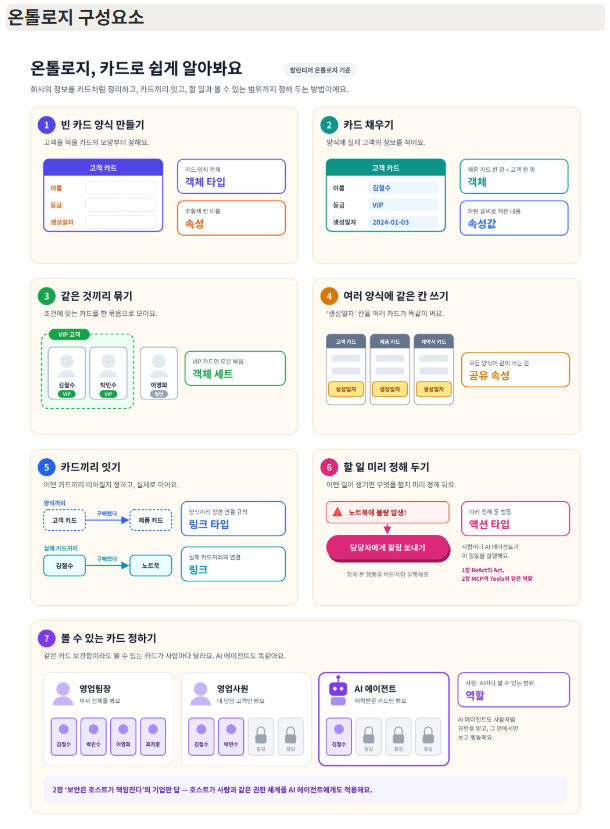  


| 구분 | 개념 | 의미 | 예시 |
|---|---|---|---|
| 객체 | 객체 타입 | 테이블의 스키마 | 고객시트 그 자체(고객 = 이름, 등급 ,생성일자를 가진 틀) |
| 객체 | 객체 | 테이블의 한 행 | 고객A, 제품B 같은 실제 인스턴스 |
| 객체 | 객체 세트 | 여러 객체의 모음 | VIP 고객 전체 |
| 속성 | 속성 | 테이블의 열 (객체가 가진 특징) | 이름, 날짜, 금액 |
| 속성 | 속성값 | 특정 객체가 가지는 속성의 실제 값 | 김철수, VIP, 2024-03-01 |
| 속성 | 공유 속성 | 여러 객체 타입에서 공통으로 쓰는 속성 | '생성일자'를 고객, 제품, 계약서 모두에서 일관되게 관리 |
| 링크 | 링크 타입 | 관계의 스키마 | '구매했다', '담당한다' |
| 링크 | 링크 | 실제 관계의 인스턴스 | '고객A가 제품B를 구매했다' |
| 액션 | 액션 타입 | 데이터 읽기를 넘어 실제 변경, 행동까지 온톨로지 위에서 정의 | '불량 발생 시 담당자에게 알림 발송' |
| 역할 | 역할 (Roles) | 직급, 부서, 지역에 따라 객체 단위까지 접근 권한 제어 | AI 에이전트도 사람처럼 권한을 받고, 부여받은 범위 안의 데이터만 조회, 실행 |


## 4. XAI  
> XAI? (Explainable AI, XAI) 설명 가능한 인공지능   

### 4-1 블랙박스가 문제인 이유   

딥러닝 모델은 수백만 ~ 수십억 개의 숫자(파라미터)가 복잡하게 얽혀 있어서, 사람이 직접 읽을 수 없음. 입력을 넣으면 출력이 나오지만 그 사이 과정은 사실상 블랙박스!  

단순히 '알면 더 좋은' 수준의 문제가 아닌 이유? : 규제 떄문!  

| 분야 | 규제 내용 |
| --- | --- |
| 🏥 의료 | FDA는 진단 AI에 결론뿐 아니라 근거 요구. 설명 없이는 인허가 X |
| 💳 금융 | EU AI Act는 대출, 보험, 채용 AI가 불리한 결정을 내렸을 때 고객에게 이유를 설명할 법적 의무를 부과, 현업에서도 Tree 계열 앙상블은 활발하게 쓰이나 딥러닝 계열은 아직 설명력이 더 필요한 단계 |
| 🚗 자율주행 | 사고 발생 시 왜 그 판단을 했는지 재현 및 설명이 가능해야 책임 소재 판단 가능 |  

+) 실용적인 이유도 존재. 모델이 잘못 학습했을 때 어디가 문제인지 디버깅 하기 위해선 내부를 봐야함!  

### 4-2 기존 해결 시도들    

1. 회귀분석 - 완전한 화이트 박스  
- 가장 고전적인 방법, 결과 = a x 나이 + b x 소득 + c x 신용점수... 처럼 계수를 직접 읽을 수 있음  
- 한계 : 복잡한 패턴에선 선형모델로 충분한 적확도를 내기 어려움  

2. SHAP / LIME - 사후적 설명(Post - hoc Explanation)  
- 딥러닝 모델은 그대로 놔두고, 외부에서 '어떤 입력 특성이 이 결과에 얼마나 기여했는지'를 계산해서 보여주는 방법  
- 한계 : 모델이 실제로 하는 연산을 설명하는 게 아니라, 입력을 조금씩 바꿔보며 역으로 추정하는 방법이므로, 진짜 이유가 아니라 그렇게 보이는 것일 수 있음  

3. LLM + RAG - 블랙박스로 블랙박스 설명하기  
- 모델의 출력과 입력 데이터를 GPT에게 넘기고 왜 이런 결정을 내렸는지 묻는 방식  
- 한계 : GPT 자체도 블랙박스이므로, 블랙박스가 블랙박스를 설명하는 셈. GPT가 그럴듯한 설명을 생성해줄 수는 있지만, 그게 딥러닝 모델의 실제 내부 연산과 일치한다는 보장 X  


### 4-3 Mechanistic Interpretability(기계적 해석 가능성)    
그렇다면 '블랙박스 자체를 열어버리면 어떨까?' -> Mechanistic Interpretability  
-> 모델이 무엇을 출력하는가가 아니라, 모델이 어떻게 그 답에 도달하는가를 이해하자!  

> Mechanistic Interpretability? 딥러닝 모델의 내부(가중치, 뉴런, 어텐션 헤드)를 직접 분석해서, 특정 기능이 모델 안 어디에 어떻게 구현되어 있는지 회로(circuit)수준까지 역공학(reverse engineering)하는 연구 분야  

**일반 XAI vs Mechanistic Interpretability**  

|  | 일반 XAI (SHAP, LIME 등) | Mechanistic Interpretability |
| --- | --- | --- |
| 접근 방식 | 외부에서 관찰 | 내부를 직접 해부 |
| 핵심 질문 | 이 입력이 결과에 중요했나 | 이 뉴런이 어떤 연산을 수행하나 |
| 분석 수준 | 입력-출력 관계 | 가중치, 회로 수준 |
| 성격 | 사후적(post-hoc) | 구조적(mechanistic) |
| 비유 | 외부에서 집 창문으로 들여다보기 | 집 구조도를 직접 그리기 |  

**핵심 기법 : Activation Patching(활성값 패칭)**  
모델 내부의 어느 위치가 답을 결정하는지를 찾는 방법  
1. 입력 두개를 준비(A, B)    
2. B를 처리하는 도중, 특정 위치의 값을 A의 값으로 바꿔 끼움  
3. 출력이 어떻게 바뀌는지 관찰  

### 4-3 핵심개념 3가지   
1. 모델 안에는 무엇이 있는가? -> Feature(특징)  
> Feature : 모델이 입력에서 알아챈 개념  
입력에 그 개념이 등장하면 해당 뉴런(또는 뉴런 조합)이 켜짐(활성값 증가)  
But, 현실에선 뉴런 하나에 개념하나가 깔끔하게 담기는 경우는 드뭄. 오히려 뉴런 하나에 서로 관계없는 여러개념이 섞여있는 경우가 많음  

2. 그것들이 어떻게 연결되어 일하는가? Circuits(회로)  
> circuit : 개별 뉴런을 넘어, 여러 뉴런/어텐션 헤드가 연결되어 특정 기능을 수행하는 서브네트워크  

- e.g. 간접 목적어 인식 회로  
  어텐션 헤드 A -> 문장에서 주어를 탐지
  어텐션 헤드 B -> 동사를 탐지
  어텐션 헤드 C -> 주어 + 동사 정보를 조합 -> 간접 목적어 위치 예측  

회로 발견시, '이 기능을 제거', '이 기능을 다른 모델에 이식'하는 식의 조작이 이론적으로 가능해짐  

3. 그런데 왜 해석하기 어렵나? Superposition(중첩)  
인간의 뇌 뉴런 수 약 860억개 but, GPT의 뉴런수 수심만개  
-> 하나의 뉴런이 여러개의 개념을 중첩해서 저장  
    1. 모델은 개념(특징)을 뉴런 하나가 아니라 활성 공간 안의 방향으로 표현  
    2. 만약 공간이 2차원이면 서로 전혀 겹치지 않는 (직교하는) 방향은 2개 밖에  
       없음 -> 특징이 2개면 깔끔하게 하나씩 배정 가능  
    3. 표현해야 할 특징이 5개라면, 모델은 5개 방향을 조금씩 겹치게 배치  
    4. 겹치니까 한 특징을 읽을 때 다른 특징이 조금 섞여 들어오는데, 이것이 간섭(interface). 
    5. 모델이 간섭을 감수하는 이유는 특징이 드물게(sparse) 나타나기 때문. 5개가 동시에 켜지는 일은 거의 없어서, 대부분의 경우 간섭이 문제를 일으키지 않으므로 손해보다 더 많은 특징을 담는 이득이 큼  
    6. 이 특징 방향들이 뉴런 축(좌표축)과 맞지 않으니, 뉴런 하나를 보면 여러 특징이 조금씩 걸쳐 보이게 됨  
-> 이를 해결하기 위해 중첩된 개념들을 수학적으로 분리해서 각 개념을 독립적으로 추출하는 Sparse Autoencoder(SAE)방법 

**Q. 왜 지금 중요한가?**  
-> AI 안전(AI safety)과의 연결  

AI 모델이 실제로 어떤 내부 목표를 가지고 연산하는지, 즉 우리가 원하는 대로 작동하는지, 아니면 우리가 모르는 방향으로 최적화하고 있는지 알아낼 수 있는 수단


